# Social dimensions of Eaton and Palisades fires
### Week 8 - Discussion section 

In January 2025, the Eaton and Palisades fires burned thousands of homes in Los Angeles County. A wildfire's impact depends not only on where it burns but also on who lives there: communities differ in their resources to evacuate, recover and rebuild. Here we combine fire perimeters with the Environmental Justice Index to look at the social dimensions of these two fires.

**Data.**
- Fire perimeters for the Eaton and Palisades fires from the [County of Los Angeles](https://www.arcgis.com/home/item.html?id=ad51845ea5fb4eb483bc2a7c38b2370c), saved as GeoJSON in `data/`.
- 2024 Environmental Justice Index for California in geodatabase format, downloaded from [ATSDR](https://www.atsdr.cdc.gov/place-health/php/eji/eji-data-download.html), saved in `data/EJI_2024_California/`.

**Packages.** `pandas`, `geopandas`, `matplotlib`, `contextily` (all in the EDS 220 environment).

## Setup

In [18]:
import os
for key in ['PROJ_LIB', 'PROJ_DATA']:
    os.environ.pop(key, None)

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx

## About the data

The [Environmental Justice Index (EJI)](https://www.atsdr.cdc.gov/place-health/php/eji/index.html) ranks every census tract in the United States on 36 environmental, social and health factors, grouped into three modules:

| Module | What it measures |
|--------|------------------|
| Social vulnerability (SVM) | Racial/ethnic minority status, socioeconomic status, household characteristics, housing type |
| Environmental burden (EBM) | Air pollution, hazardous sites, built environment, transportation, water pollution |
| Health vulnerability (HVM) | Pre-existing chronic disease burden |

The 2024 release also includes a climate burden module (CBM).

Column name prefixes:
- `E_`: estimates (e.g. `E_NOINT` = percentage of persons without internet)
- `EPL_`: percentile ranks of those estimates, 0 to 1
- `SPL_`: summed ranks for domains, modules or overall score
- `RPL_`: percentile ranks for domains, modules or overall score

Values of -999 mean no data. Census tract boundaries come from the 2020 TIGER/Line Files.

## 1. Metadata exploration

### 1a. Load the data dictionary

In [34]:
# skiprows=1: the first row is a note about the dataset, not column names
# encoding='cp1252': the file uses Windows text encoding
eji_dictionary = pd.read_csv(
    'data/EJI_2024_California/EJI_2024_California/EJI_DATADICTIONARY_2024.csv',
    skiprows=1,
    encoding='cp1252'
)

eji_dictionary.head()

,2024 VARIABLE NAME,2022 VARIABLE NAME,2024 VARIABLE DESCRIPTION,MODULE,DOMAIN,DATA SOURCE,2024 TABLE FIELD CALCULATION,NOTES
0,STATEFP,STATEFP,State Federal Information Processing Series (FIPS) code,No Value,No Value,No Value,No Value,No Value
1,COUNTYFP,COUNTYFP,County FIPS code,No Value,No Value,No Value,No Value,No Value
2,TRACTCE,TRACTCE,Census tract geographic code,No Value,No Value,The U.S. Census Bureau 2020 Cartographic Boundary files\n\nhttps://www.census.gov/geographies/ \nmapping-files/time-...,No Value,No Value
3,AFFGEOID,AFFGEOID,"Census tract identifier; a concatenation of current state Federal Information Processing Series (FIPS) code, county ...",No Value,No Value,No Value,No Value,No Value
4,GEOID,GEOID,"11-digit census tract identifier, which is a concatenation of the 2-digit state FIPS code, 3-digit county FIPS code,...",No Value,No Value,No Value,"2020 State FIPS + 2020 County FIPS + 2020 Census Tract Code (All States, except Connecticut)\nFor Connecticut tracts...",Connecticut tracts are using updated 2022 County FIPS codes. All other tracts are using 2020 FIPS codes.


### 1b. What is `eji_dictionary`?

Each row describes one variable in the EJI dataset. The columns are:

| Column | Description |
|--------|-------------|
| `2024 VARIABLE NAME` | Column name in the EJI geodatabase |
| `2024 VARIABLE DESCRIPTION` | What the variable measures |
| `MODULE` | Which EJI module (SVM, EBM, HVM, CBM, or general identifiers) |
| `DOMAIN` | Sub-domain within the module |
| `DATA SOURCE` | Where the underlying data comes from (e.g. ACS, CDC, EPA) |

In [35]:
print(f"The data dictionary has {eji_dictionary.shape[0]} rows and {eji_dictionary.shape[1]} columns.")
print(f"Columns: {list(eji_dictionary.columns)}")

The data dictionary has 170 rows and 8 columns.
Columns: ['2024 VARIABLE NAME', '2022 VARIABLE NAME', '2024 VARIABLE DESCRIPTION', 'MODULE', 'DOMAIN', 'DATA SOURCE', '2024 TABLE FIELD CALCULATION', 'NOTES']


### 1c. Filter to Social Vulnerability Module (SVM)

The code below filters the data dictionary to show only the variables in the Social Vulnerability Module.

In [36]:
# Remove leading/trailing whitespace from variable names
eji_dictionary['2024 VARIABLE NAME'] = eji_dictionary['2024 VARIABLE NAME'].str.strip()

# Widen the display so descriptions are not truncated
pd.set_option('display.max_colwidth', 120)

# Filter: keep rows where MODULE is 'SVM', show three columns
eji_dictionary.loc[
    eji_dictionary['MODULE'] == 'SVM',
    ['2024 VARIABLE NAME', '2024 VARIABLE DESCRIPTION', 'DOMAIN']
]

,2024 VARIABLE NAME,2024 VARIABLE DESCRIPTION,DOMAIN
19,E_MINRTY,"Percentage of persons who identify as Hispanic or Latino (of any race); Black and African American, Not Hispanic or ...",SVM DOM1
20,EPL_MINRTY,Percentile rank of percentage of persons who identify as Hispanic or Latino (of any race); Black and African America...,SVM DOM1
21,SPL_SVM_DOM1,Domain consisting of the percentage of persons who identify as Hispanic or Latino (of any race); Black and African A...,SVM DOM1
22,RPL_SVM_DOM1,Percentile rank of domain consisting of the percentage of persons who identify as Hispanic or Latino (of any race); ...,SVM DOM1
23,E_POV200,Percentage of persons with income below 200% of the federal poverty level,SVM DOM2
24,EPL_POV200,Percentile rank of the percentage of persons with income below 200% of federal poverty level,SVM DOM2
25,E_NOHSDP,Percentage of persons with no high school diploma (age 25+),SVM DOM2
26,EPL_NOHSDP,Percentile rank of percentage of persons with no high school diploma (age 25+),SVM DOM2
27,E_UNEMP,Percentage of persons who are unemployed,SVM DOM2
28,EPL_UNEMP,Percentile rank of the percentage of persons who are unemployed,SVM DOM2


Line-by-line:
1. `.str.strip()` removes whitespace from the variable name strings so that later comparisons work reliably.
2. `pd.set_option('display.max_colwidth', 120)` widens the column display so the long descriptions are not cut off with `...`.
3. `.loc[condition, columns]` filters to rows where `MODULE == 'SVM'` and selects three columns.

The SVM module has four domains:

| Domain | Contents |
|--------|----------|
| SVM DOM1 | Minority status and language |
| SVM DOM2 | Socioeconomic status (poverty, education, unemployment, renters, housing burden, uninsured, no internet) |
| SVM DOM3 | Household characteristics and disability (age 65+, age 17 and under, disability, single-parent households) |
| SVM DOM4 | Housing type and transportation (multi-unit, mobile homes, crowding, no vehicle, group quarters) |

### 1d. Variables that could affect a community's wildfire response

The [EJI technical documentation](https://www.atsdr.cdc.gov/place-health/media/pdfs/2024/10/EJI_2024_Technical_Documentation.pdf) describes each indicator (pages 40-41 list all indicators, pages 43-60 cover the social vulnerability indicators).

| Variable | Description | Relevance to wildfire response |
|----------|-------------|--------------------------------|
| `EPL_POV200` | % below 200% poverty line | Fewer resources to evacuate, find temporary housing or rebuild |
| `EPL_RENTER` | % renter-occupied housing | Renters typically lack homeowner's insurance and cannot modify building materials |
| `EPL_HOUBDN` | % housing cost-burdened | Households already stretched by housing costs have less financial cushion for fire-related expenses |
| `EPL_NOINT` | % without internet | Missed evacuation alerts, difficulty accessing FEMA applications and relief information |
| `EPL_UNINSUR` | % uninsured | Medical costs from smoke inhalation or burns fall entirely on the household |
| `EPL_MINRTY` | % racial/ethnic minority | Historical disinvestment can mean less fire-resistant infrastructure and slower emergency response |



## 2. Polygon intersection

### 2a. Load and explore the data

In [37]:
# Load fire perimeters
palisades = gpd.read_file('data/palisades_perimeter_20250121.geojson')
eaton = gpd.read_file('data/eaton_perimeter_20250121.geojson')

# Load EJI data
eji = gpd.read_file('data/EJI_2024_California/EJI_2024_California/EJI_2024_California.gdb')

print(f"Palisades: {palisades.shape[0]} polygon(s), CRS = EPSG:{palisades.crs.to_epsg()}")
print(f"Eaton:     {eaton.shape[0]} polygon(s), CRS = EPSG:{eaton.crs.to_epsg()}")
print(f"EJI:       {eji.shape[0]} census tracts, {eji.shape[1]} columns, CRS = {eji.crs}")

Palisades: 1 polygon(s), CRS = EPSG:4326
Eaton:     1 polygon(s), CRS = EPSG:4326
EJI:       9109 census tracts, 174 columns, CRS = PROJCS["USA_Contiguous_Albers_Equal_Area_Conic",GEOGCS["NAD83",DATUM["North_American_Datum_1983",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6269"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4269"]],PROJECTION["Albers_Conic_Equal_Area"],PARAMETER["latitude_of_center",37.5],PARAMETER["longitude_of_center",-96],PARAMETER["standard_parallel_1",29.5],PARAMETER["standard_parallel_2",45.5],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["ESRI","102003"]]


The fire perimeters are in EPSG:4326 (geographic, lat/lon). The EJI data uses an Albers Equal Area projection. Before any spatial operation, all layers must share the same CRS.

In [38]:
# Reproject EJI to EPSG:4326 to match the fire perimeters
eji_4326 = eji.to_crs(epsg=4326)

### 2b. Spatial join: Palisades fire

`gpd.sjoin()` keeps census tracts whose geometry intersects the fire perimeter. It returns entire tracts, even if only a small portion overlaps.

In [24]:
palisades_sjoin = gpd.sjoin(eji_4326, palisades, how='inner', predicate='intersects')

print(f"Census tracts intersecting Palisades fire: {len(palisades_sjoin)}")

Census tracts intersecting Palisades fire: 15


### 2c. Map: Palisades intersecting tracts and fire perimeter

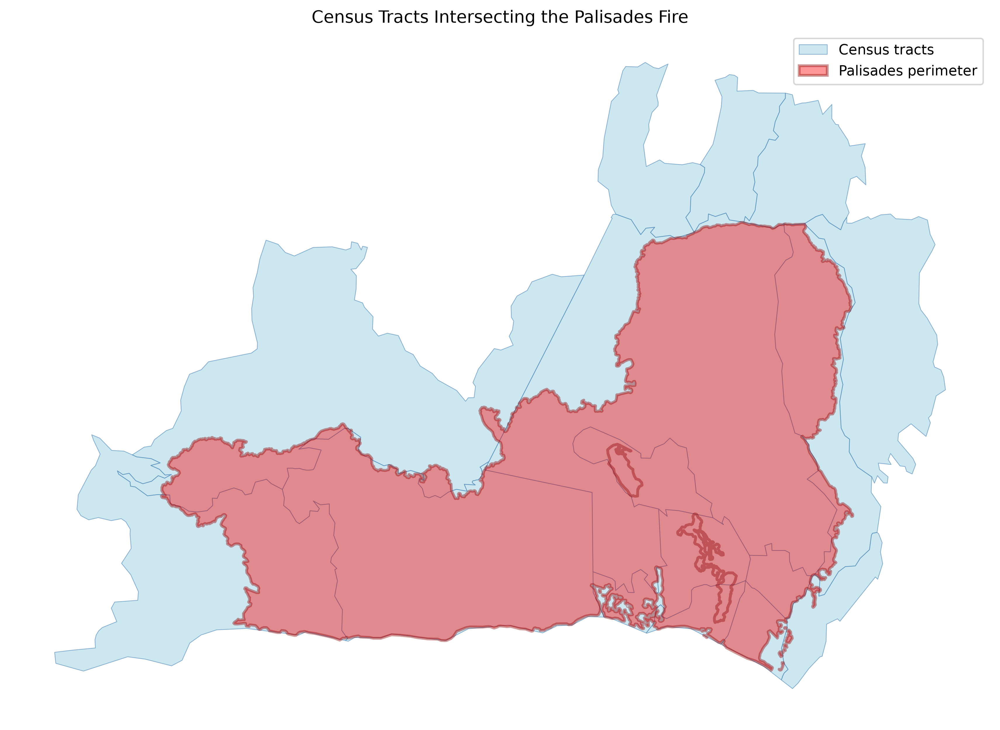

In [40]:
fig, ax = plt.subplots(1, 1, figsize=(10, 10))

palisades_sjoin.plot(ax=ax, color='lightblue', edgecolor='steelblue',
                     linewidth=0.5, alpha=0.6, label='Census tracts')
palisades.plot(ax=ax, color='red', alpha=0.4, edgecolor='darkred',
               linewidth=2, label='Palisades perimeter')

ax.set_title('Census Tracts Intersecting the Palisades Fire')
ax.legend()
ax.axis('off')
plt.tight_layout()
plt.show()

The Palisades fire perimeter is much smaller than the combined area of the intersecting census tracts. The spatial join returns entire tracts that only partially overlap with the burn area, so the "affected" area is a significant overestimate of the actual burned footprint.

### 2d. Spatial join and map: Eaton fire

In [41]:
eaton_sjoin = gpd.sjoin(eji_4326, eaton, how='inner', predicate='intersects')

print(f"Census tracts intersecting Eaton fire: {len(eaton_sjoin)}")

Census tracts intersecting Eaton fire: 18


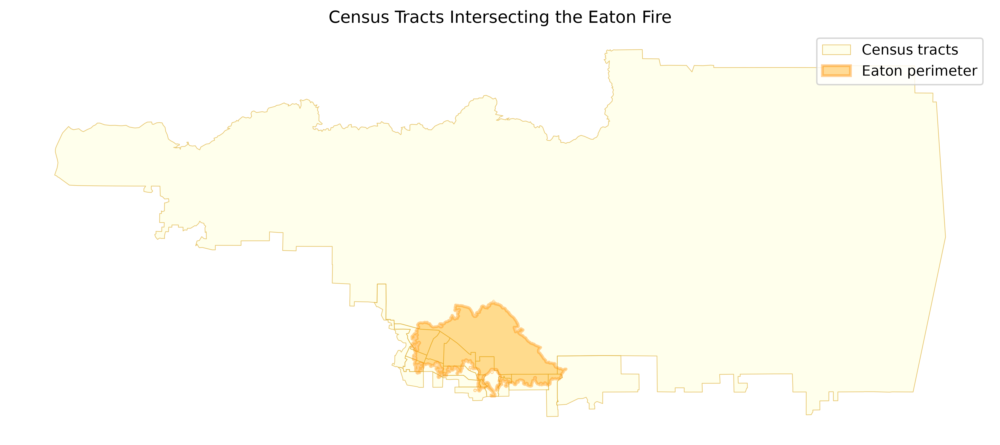

In [42]:
fig, ax = plt.subplots(1, 1, figsize=(10, 10))

eaton_sjoin.plot(ax=ax, color='lightyellow', edgecolor='goldenrod',
                 linewidth=0.5, alpha=0.6, label='Census tracts')
eaton.plot(ax=ax, color='orange', alpha=0.4, edgecolor='darkorange',
           linewidth=2, label='Eaton perimeter')

ax.set_title('Census Tracts Intersecting the Eaton Fire')
ax.legend()
ax.axis('off')
plt.tight_layout()
plt.show()

The Eaton perimeter is also smaller than the combined intersecting tracts. The Eaton fire burned through more densely populated foothill communities near Altadena, where census tracts are geographically smaller (tracts are drawn to have roughly equal population, so denser areas produce smaller tracts). The mismatch between perimeter and tracts is still visible but less dramatic than for Palisades.

## 3. Polygon clipping

### 3a-b. Clip census tracts to each fire perimeter

`gpd.clip()` trims the tract geometries to the boundary of the fire perimeter polygon. Only the portions inside the perimeter are kept.

In [43]:
palisades_clip = gpd.clip(eji_4326, palisades)
eaton_clip = gpd.clip(eji_4326, eaton)

print(f"Palisades -- sjoin: {len(palisades_sjoin)} tracts, clip: {len(palisades_clip)} tract fragments")
print(f"Eaton     -- sjoin: {len(eaton_sjoin)} tracts, clip: {len(eaton_clip)} tract fragments")

Palisades -- sjoin: 15 tracts, clip: 15 tract fragments
Eaton     -- sjoin: 18 tracts, clip: 18 tract fragments


### 3c. Visualize clipped tracts

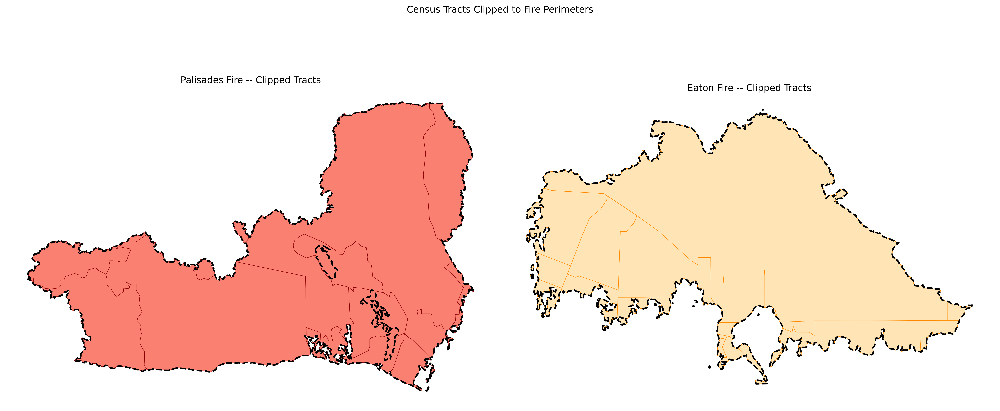

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

palisades_clip.plot(ax=axes[0], color='salmon', edgecolor='darkred', linewidth=0.5)
palisades.boundary.plot(ax=axes[0], color='black', linewidth=2, linestyle='--')
axes[0].set_title('Palisades Fire -- Clipped Tracts')
axes[0].axis('off')

eaton_clip.plot(ax=axes[1], color='moccasin', edgecolor='darkorange', linewidth=0.5)
eaton.boundary.plot(ax=axes[1], color='black', linewidth=2, linestyle='--')
axes[1].set_title('Eaton Fire -- Clipped Tracts')
axes[1].axis('off')

plt.suptitle('Census Tracts Clipped to Fire Perimeters', y=1.02)
plt.tight_layout()
plt.show()

**Spatial join vs. clipping.**

A spatial join (`sjoin`) keeps entire geometries from the left GeoDataFrame that satisfy a spatial relationship with the right GeoDataFrame. If a census tract barely touches the fire perimeter, the entire tract is included.

Clipping (`clip`) cuts the left geometries to the boundary of the right geometry. Only the portions of tracts that fall inside the fire perimeter are kept.

**After clipping, do the EJI values describe the people inside the fire perimeter or the whole tract?**

The EJI values still describe the entire original census tract. If a tract is only 10% inside the fire perimeter, the clipped polygon carries the same `EPL_POV200` value as the full tract. Clipping changes the geometry but not the attributes. This means:

- The spatial join overestimates the area affected but correctly associates data with the communities those tracts represent.
- Clipping gives a more precise geographic footprint but the attribute values are still tract-level averages.

Changing the geometry does not change the statistical unit the data describes. We should understand this distinction before choosing which result to use in section 5.

## 4. Visualize fire perimeters with a basemap

### 4a. Import contextily

`contextily` was imported as `ctx` in the setup cell.

### 4b. Plot perimeters with a basemap

Fill in the fire perimeters, a legend or annotation, and a title. The completed version:

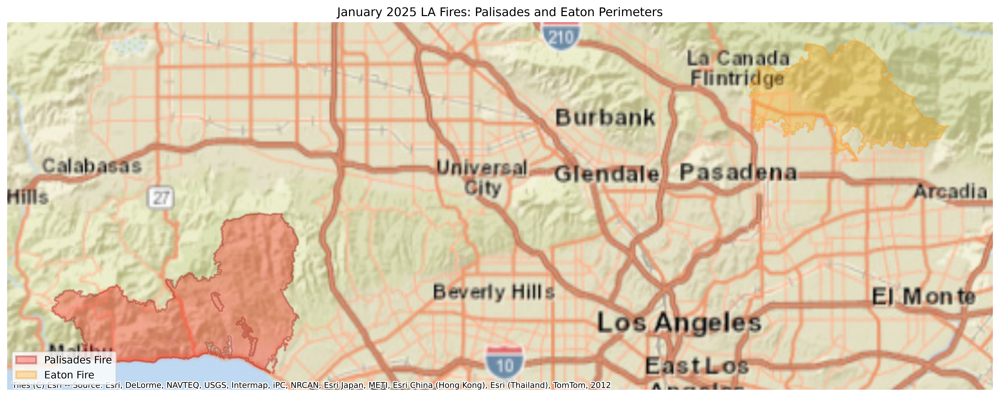

In [45]:
fig, ax = plt.subplots(1, 1, figsize=(14, 12))

# Plot fire perimeters with transparency
palisades.plot(ax=ax, color='red', alpha=0.3, edgecolor='darkred',
               linewidth=2, label='Palisades Fire')
eaton.plot(ax=ax, color='orange', alpha=0.3, edgecolor='darkorange',
           linewidth=2, label='Eaton Fire')

# Add legend
ax.legend(loc='lower left')

# Add basemap: pass the CRS of the perimeters so tiles align
ctx.add_basemap(ax, crs=palisades.crs, source=ctx.providers.Esri.WorldStreetMap)

# Add title
ax.set_title('January 2025 LA Fires: Palisades and Eaton Perimeters')

ax.axis('off')
plt.tight_layout()
plt.show()

## 5. Visualize EJI data

### 5a. Choose tracts and justify

In [46]:
palisades_tracts = palisades_sjoin.copy()
eaton_tracts = eaton_sjoin.copy()

We use the spatial join tracts rather than the clipped tracts. The EJI values describe whole census tracts, not sub-tract areas. Clipping changes the geometry but not what the data represents. Using whole tracts is more honest about the unit of analysis: the community described by each data point extends beyond the fire perimeter, and that community's resources and vulnerabilities are what matter for disaster response.

Either choice is defensible. The key is to understand and articulate the trade-off.

### 5b. Plot an EJI variable

First, replace -999 (no data) with NaN so those tracts do not distort the color scale.

In [32]:
palisades_tracts = palisades_tracts.replace(-999, float('nan'))
eaton_tracts = eaton_tracts.replace(-999, float('nan'))

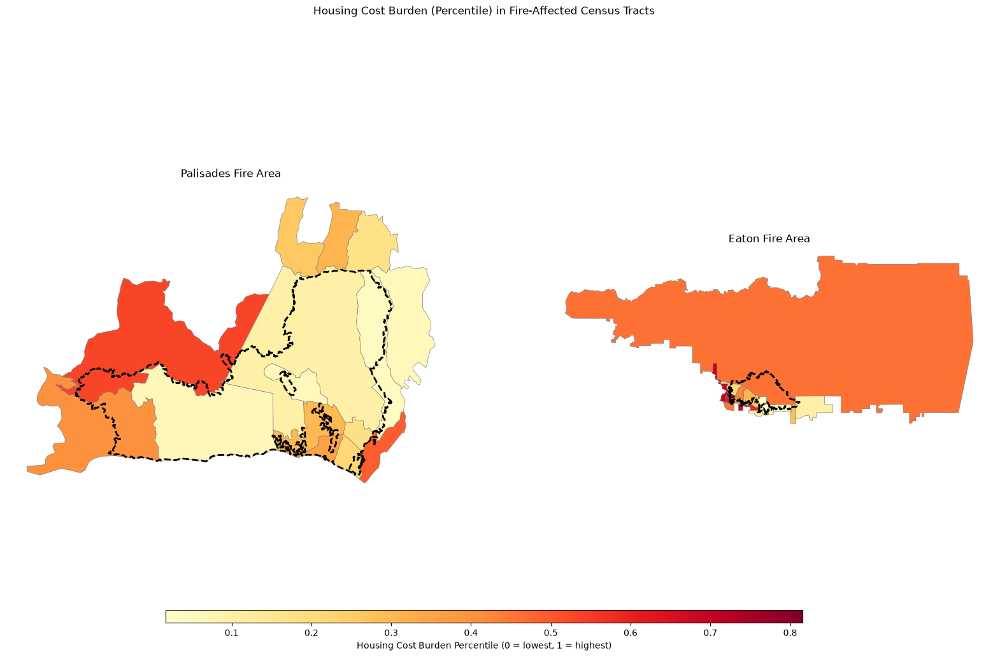

In [33]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 10))

eji_variable = 'EPL_HOUBDN'

# Common min/max for a shared color scale
vmin = min(palisades_tracts[eji_variable].min(), eaton_tracts[eji_variable].min())
vmax = max(palisades_tracts[eji_variable].max(), eaton_tracts[eji_variable].max())

# Palisades
palisades_tracts.plot(
    column=eji_variable,
    cmap='YlOrRd',
    vmin=vmin, vmax=vmax,
    legend=False,
    edgecolor='gray', linewidth=0.5,
    ax=ax1,
)
palisades.boundary.plot(ax=ax1, color='black', linewidth=2, linestyle='--')
ax1.set_title('Palisades Fire Area')
ax1.axis('off')

# Eaton
eaton_tracts.plot(
    column=eji_variable,
    cmap='YlOrRd',
    vmin=vmin, vmax=vmax,
    legend=False,
    edgecolor='gray', linewidth=0.5,
    ax=ax2,
)
eaton.boundary.plot(ax=ax2, color='black', linewidth=2, linestyle='--')
ax2.set_title('Eaton Fire Area')
ax2.axis('off')

fig.suptitle('Housing Cost Burden (Percentile) in Fire-Affected Census Tracts', y=1.02)

# Shared colorbar
sm = plt.cm.ScalarMappable(cmap='YlOrRd', norm=plt.Normalize(vmin=vmin, vmax=vmax))
cbar_ax = fig.add_axes([0.25, 0.05, 0.5, 0.02])
cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')
cbar.set_label('Housing Cost Burden Percentile (0 = lowest, 1 = highest)')

plt.show()

**Distribution comparison.**

The Palisades fire area (Pacific Palisades, Malibu, Topanga) tends to have lower housing cost burden percentiles. These are wealthier communities where households generally earn enough that housing costs do not exceed 30% of income.

The Eaton fire area (Altadena, foothills northeast of Pasadena) shows more variation and somewhat higher housing cost burden in several tracts. These communities include a mix of income levels, with some tracts containing significantly cost-burdened households.

For wildfire relief policy cost-burdened households have less financial cushion to absorb the costs of evacuation, temporary housing and rebuilding. Relief programs may need to be calibrated differently for the two fire areas.

**What the data cannot tell us.**

1. The EJI values describe entire census tracts (typically 1,200 to 8,000 people). Within a single tract there can be large variation. We cannot say anything about individual households from tract-level data.

2. The EJI data was compiled from pre-fire sources (primarily 2018-2022 American Community Survey estimates). The data describes who lived there before the fire, not who is there now or who was physically present during the event.